# 04 · Modelagem preditiva

**Autor:** Renato Colin Neto · **Fase CRISP-DM:** modelagem e avaliação

Objetivo da etapa: treinar classificadores que preveem se um ciclo de usinagem termina em
falha, escolher o melhor por validação cruzada no treino, medir o escolhido **uma única vez**
no teste e entender o que ele aprendeu. As probabilidades geradas aqui alimentam a análise de
custo do notebook 05.

Desenho experimental, em resumo: 5 modelos × 2 conjuntos de atributos em validação cruzada
estratificada de 5 dobras, com PR-AUC como métrica principal; ajuste de hiperparâmetros só do
melhor; avaliação final no teste; recall por modo de falha; importância por permutação e uma
árvore rasa para interpretação.

In [1]:
# Ambiente: coloca src/ no sys.path (o notebook roda a partir de notebooks/ ou da raiz)
import sys
from pathlib import Path

RAIZ = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(RAIZ / "src"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
from sklearn.tree import export_text, plot_tree

from manutencao import modelagem as mo
from manutencao.config import (
    ATRIBUTOS_BRUTO,
    ATRIBUTOS_ENGENHARIA,
    COLS_MODOS,
    DIR_TABELAS,
    SEED,
)
from manutencao.preparacao import carregar_preparado, dividir_treino_teste, separar_x_y
from manutencao.util import configurar_graficos, salvar_figura, salvar_tabela

configurar_graficos()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)

ROTULOS = {
    "dummy": "Dummy",
    "regressao_logistica": "Regressão\nlogística",
    "arvore_decisao": "Árvore de\ndecisão",
    "random_forest": "Random\nForest",
    "gradient_boosting": "HistGradient\nBoosting",
}

In [3]:
df = carregar_preparado()
treino, teste = dividir_treino_teste(df)
CONJUNTOS = {"bruto": ATRIBUTOS_BRUTO, "engenharia": ATRIBUTOS_ENGENHARIA}
X_tr, y_tr = separar_x_y(treino, ATRIBUTOS_ENGENHARIA)
print(f"treino: {len(treino)} ciclos, {int(y_tr.sum())} falhas ({100 * y_tr.mean():.2f} %)")
print(f"teste:  {len(teste)} ciclos (guardado até a seção 5)")
for nome, atributos in CONJUNTOS.items():
    print(f"conjunto {nome!r} ({len(atributos)} atributos): {atributos}")

treino: 8000 ciclos, 271 falhas (3.39 %)
teste:  2000 ciclos (guardado até a seção 5)
conjunto 'bruto' (6 atributos): ['tipo', 'temp_ar_k', 'temp_processo_k', 'rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']
conjunto 'engenharia' (9 atributos): ['tipo', 'temp_ar_k', 'temp_processo_k', 'rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min', 'dif_temperatura_k', 'potencia_w', 'esforco_ferramenta_min_nm']


## 1. Desenho experimental

- **Tarefa:** classificação binária do alvo `falha` (aprendizado supervisionado).
- **Dados:** só o **treino** (8.000 ciclos) é usado para comparar e ajustar os modelos. O
  **teste** (2.000 ciclos) fica guardado e é usado **uma única vez**, na seção 5, com o modelo
  já escolhido. Se o teste servisse para escolher modelo ou hiperparâmetro, a métrica final
  ficaria otimista: estaríamos medindo a nota da prova que usamos para estudar.
- **Validação:** `StratifiedKFold` com 5 dobras, embaralhada com `SEED = 42`. Cada dobra mantém
  a proporção de falhas do treino. O pré-processamento fica **dentro** do `Pipeline`, então é
  reajustado em cada dobra só com os dados de treino daquela dobra (sem vazamento).
- **Métrica principal: PR-AUC** (*average precision*). Com 3,39 % de positivos, a ROC-AUC fica
  alta mesmo com muitos falsos alarmes, porque a taxa de falsos positivos é dividida pelos
  milhares de ciclos sem falha; a curva precisão-recall olha só para a classe rara e tem como
  piso a prevalência (SAITO; REHMSMEIER, 2015). Também medimos ROC-AUC, recall, precisão, F1,
  MCC (CHICCO; JURMAN, 2020) e acurácia balanceada, as quatro últimas com limiar 0,5.
- **Desbalanceamento:** `class_weight="balanced"` (os erros na classe rara pesam mais no
  treino). Sem reamostragem sintética: é mais simples e não cria risco de vazar informação
  entre dobras.
- **Modelos** (todos do scikit-learn, PEDREGOSA *et al.*, 2011):
  - **Dummy** (prevê a prevalência): piso que qualquer modelo útil precisa superar;
  - **Regressão Logística**: modelo linear, com padronização dos atributos numéricos;
  - **Árvore de Decisão** (profundidade 6): regras legíveis;
  - **Random Forest** (BREIMAN, 2001): média de 300 árvores, reduz a variância da árvore única;
  - **HistGradientBoosting** (FRIEDMAN, 2001): árvores em sequência, cada uma corrigindo os
    erros das anteriores.
- **Ablação de atributos:** `bruto` (tipo + 5 leituras de sensor) × `engenharia` (+ diferença de
  temperatura, potência e esforço da ferramenta). Mostra quanto o conhecimento do domínio vale.
- **Ajuste de hiperparâmetros:** `RandomizedSearchCV` com 15 combinações, PR-AUC e a mesma
  validação, só no modelo de maior PR-AUC média com `engenharia`.

## 2. Comparação dos modelos (validação cruzada no treino)

In [4]:
comp = mo.comparar_modelos(treino, CONJUNTOS)
salvar_tabela(comp, "04_comparacao_cv")
comp[
    [
        "modelo",
        "conjunto",
        "pr_auc_media",
        "pr_auc_dp",
        "roc_auc_media",
        "recall_media",
        "precisao_media",
        "f1_media",
        "mcc_media",
        "tempo_ajuste_s",
    ]
].round(3)

,modelo,conjunto,pr_auc_media,pr_auc_dp,roc_auc_media,recall_media,precisao_media,f1_media,mcc_media,tempo_ajuste_s
0,gradient_boosting,engenharia,0.890,0.017,0.975,0.830,0.912,0.868,0.865,0.659
1,random_forest,engenharia,0.889,0.032,0.971,0.760,0.962,0.848,0.850,0.977
2,gradient_boosting,bruto,0.799,0.033,0.972,0.782,0.699,0.737,0.729,0.405
3,arvore_decisao,engenharia,0.794,0.053,0.917,0.886,0.403,0.553,0.578,0.026
4,random_forest,bruto,0.766,0.030,0.969,0.454,0.930,0.607,0.641,0.924
5,arvore_decisao,bruto,0.535,0.060,0.843,0.793,0.317,0.452,0.476,0.018
6,regressao_logistica,engenharia,0.458,0.041,0.923,0.845,0.162,0.272,0.328,0.020
7,regressao_logistica,bruto,0.443,0.027,0.897,0.801,0.136,0.232,0.281,0.016
8,dummy,bruto,0.034,0.000,0.500,0.000,0.000,0.000,0.000,0.005
9,dummy,engenharia,0.034,0.000,0.500,0.000,0.000,0.000,0.000,0.006


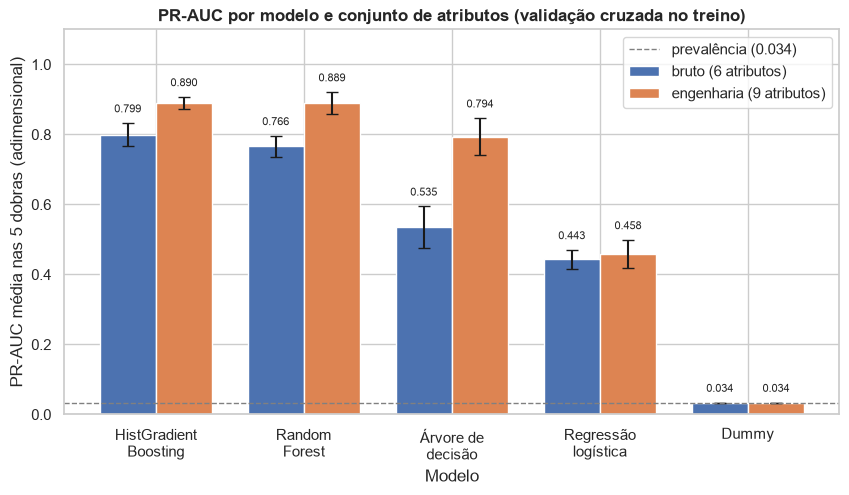

In [5]:
ordem = comp.query("conjunto == 'engenharia'")["modelo"].tolist()
largura = 0.38
x = np.arange(len(ordem))
fig, ax = plt.subplots(figsize=(10, 5))
for i, (conjunto, cor) in enumerate(zip(CONJUNTOS, sns.color_palette("deep", 2), strict=True)):
    parte = comp.query("conjunto == @conjunto").set_index("modelo").loc[ordem]
    barras = ax.bar(
        x + (i - 0.5) * largura,
        parte["pr_auc_media"],
        largura,
        yerr=parte["pr_auc_dp"],
        capsize=4,
        color=cor,
        label=f"{conjunto} ({len(CONJUNTOS[conjunto])} atributos)",
    )
    ax.bar_label(barras, fmt="%.3f", padding=6, fontsize=8)
ax.axhline(y_tr.mean(), color="gray", ls="--", lw=1, label=f"prevalência ({y_tr.mean():.3f})")
ax.set_xticks(x, [ROTULOS[m] for m in ordem])
ax.set_ylim(0, 1.1)
ax.set_xlabel("Modelo")
ax.set_ylabel("PR-AUC média nas 5 dobras (adimensional)")
ax.set_title("PR-AUC por modelo e conjunto de atributos (validação cruzada no treino)")
ax.legend(loc="upper right")
salvar_figura(fig, "04_comparacao_modelos")
plt.show()

In [6]:
# Ganho de PR-AUC média com os atributos de engenharia, por modelo
ganho = (
    comp.pivot(index="modelo", columns="conjunto", values="pr_auc_media")
    .loc[ordem, ["bruto", "engenharia"]]
    .assign(ganho=lambda t: t["engenharia"] - t["bruto"])
)
ganho.round(3)

conjunto,bruto,engenharia,ganho
modelo,,,
gradient_boosting,0.799,0.890,0.091
random_forest,0.766,0.889,0.123
arvore_decisao,0.535,0.794,0.259
regressao_logistica,0.443,0.458,0.015
dummy,0.034,0.034,0.000


**Interpretação.**

- **A engenharia de atributos melhora todos os modelos.** PR-AUC média de `bruto` →
  `engenharia`: HistGradientBoosting 0,799 → 0,890; Random Forest 0,766 → 0,889; Árvore de
  Decisão 0,535 → 0,794; Regressão Logística 0,443 → 0,458. O ganho é maior na árvore única,
  que com os atributos brutos precisaria de muitos cortes para aproximar um produto
  (potência = torque × rotação) ou uma diferença (ΔT); com o atributo pronto, um corte basta.
  Na regressão logística o ganho é pequeno porque as regras de falha são **faixas** (potência
  abaixo de 3500 W **ou** acima de 9000 W), que uma fronteira linear não separa.
- **A ROC-AUC esconde diferenças que a PR-AUC mostra.** A regressão logística com `engenharia`
  tem ROC-AUC 0,923, número que parece bom, mas precisão média de 0,162 no limiar 0,5: cerca de
  5 alarmes falsos para cada falha real. O HistGradientBoosting tem ROC-AUC quase igual com
  `bruto` (0,972) e com `engenharia` (0,975), enquanto a PR-AUC separa os dois (0,799 × 0,890).
  Por isso a PR-AUC é a métrica de escolha.
- **O piso confere:** o Dummy tem PR-AUC 0,034, a própria prevalência, e ROC-AUC 0,500.
- **Vencedor:** HistGradientBoosting com `engenharia` (0,890 ± 0,017), empatado na prática com
  o Random Forest (0,889 ± 0,032): a diferença é muito menor que o desvio entre dobras. O
  HistGradientBoosting tem desvio menor e treina mais rápido, e é o que segue para o ajuste.

## 3. Ajuste de hiperparâmetros do melhor modelo

In [7]:
melhor = comp.query("conjunto == 'engenharia' and modelo != 'dummy'").iloc[0]["modelo"]
busca = mo.ajustar_hiperparametros(melhor, ATRIBUTOS_ENGENHARIA, X_tr, y_tr)
top = (
    pd.DataFrame(busca.cv_results_)
    .sort_values("rank_test_score")
    .head(10)[["params", "mean_test_score", "std_test_score"]]
)
salvar_tabela(top, "04_busca_hiperparametros")
print("modelo ajustado:", melhor)
print("melhores hiperparâmetros:", busca.best_params_)
pr_auc_padrao = comp.query("modelo == @melhor and conjunto == 'engenharia'")["pr_auc_media"].iloc[0]
print(f"PR-AUC média (5 dobras) com os padrões: {pr_auc_padrao:.4f}")
print(f"PR-AUC média (5 dobras) com os melhores: {busca.best_score_:.4f}")
print(f"ganho do ajuste: {busca.best_score_ - pr_auc_padrao:.4f}")
top.round(4)

modelo ajustado: gradient_boosting
melhores hiperparâmetros: {'modelo__min_samples_leaf': 10, 'modelo__max_leaf_nodes': 63, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.03, 'modelo__l2_regularization': 1.0}
PR-AUC média (5 dobras) com os padrões: 0.8900
PR-AUC média (5 dobras) com os melhores: 0.8949
ganho do ajuste: 0.0049


,params,mean_test_score,std_test_score
10,"{'modelo__min_samples_leaf': 10, 'modelo__max_leaf_nodes': 63, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.03, 'modelo__l2_regularization': 1.0}",0.8949,0.0195
3,"{'modelo__min_samples_leaf': 10, 'modelo__max_leaf_nodes': 63, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.05, 'modelo__l2_regularization': 1.0}",0.8949,0.0189
1,"{'modelo__min_samples_leaf': 10, 'modelo__max_leaf_nodes': 63, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.2, 'modelo__l2_regularization': 1.0}",0.8943,0.0212
7,"{'modelo__min_samples_leaf': 20, 'modelo__max_leaf_nodes': 15, 'modelo__max_iter': 200, 'modelo__learning_rate': 0.03, 'modelo__l2_regularization': 0.1}",0.8933,0.0233
0,"{'modelo__min_samples_leaf': 10, 'modelo__max_leaf_nodes': 31, 'modelo__max_iter': 200, 'modelo__learning_rate': 0.2, 'modelo__l2_regularization': 1.0}",0.8916,0.0189
13,"{'modelo__min_samples_leaf': 10, 'modelo__max_leaf_nodes': 15, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.03, 'modelo__l2_regularization': 0.0}",0.8911,0.0213
4,"{'modelo__min_samples_leaf': 10, 'modelo__max_leaf_nodes': 63, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.03, 'modelo__l2_regularization': 0.0}",0.8909,0.0177
8,"{'modelo__min_samples_leaf': 20, 'modelo__max_leaf_nodes': 63, 'modelo__max_iter': 200, 'modelo__learning_rate': 0.2, 'modelo__l2_regularization': 1.0}",0.8904,0.0176
12,"{'modelo__min_samples_leaf': 20, 'modelo__max_leaf_nodes': 15, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.1, 'modelo__l2_regularization': 1.0}",0.8889,0.0173
2,"{'modelo__min_samples_leaf': 10, 'modelo__max_leaf_nodes': 31, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.2, 'modelo__l2_regularization': 0.1}",0.8874,0.0184


In [8]:
final = busca.best_estimator_
escolhido = pd.DataFrame(
    [
        {
            "modelo": melhor,
            "conjunto": "engenharia",
            "parametros": str(busca.best_params_),
            "pr_auc_cv": busca.best_score_,
        }
    ]
)
salvar_tabela(escolhido, "04_modelo_escolhido")
escolhido

,modelo,conjunto,parametros,pr_auc_cv
0,gradient_boosting,engenharia,"{'modelo__min_samples_leaf': 10, 'modelo__max_leaf_nodes': 63, 'modelo__max_iter': 400, 'modelo__learning_rate': 0.03, 'modelo__l2_regularization': 1.0}",0.89489


**Interpretação.** A busca escolheu taxa de aprendizado menor (0,03) com mais iterações (400),
folhas com pelo menos 10 ciclos, até 63 folhas por árvore e regularização L2 = 1,0. A PR-AUC
média subiu de 0,8900 (hiperparâmetros padrão) para 0,8949 (ganho de 0,0049), menor que o desvio entre
dobras (0,017): as 10 melhores combinações ficam todas entre 0,8874 e 0,8949. O modelo é pouco
sensível aos hiperparâmetros neste espaço; o que define o desempenho são os atributos.

## 4. Probabilidades *out-of-fold* no treino

O notebook 05 escolhe o limiar de decisão pelo custo (decisão D11). Esse limiar não pode ser
escolhido no teste, e as probabilidades do modelo sobre os próprios dados de treino são
otimistas (o modelo já viu aqueles ciclos). A saída é a predição *out-of-fold*: cada ciclo do
treino recebe a probabilidade dada por um modelo, com os hiperparâmetros escolhidos, que foi
treinado nas outras 4 dobras e nunca viu aquele ciclo.

In [9]:
oof = mo.probabilidades_oof(final, X_tr, y_tr)
oof_treino = pd.DataFrame({"udi": treino["udi"], "falha": y_tr, "proba": oof})
salvar_tabela(oof_treino, "04_oof_treino")
print("linhas:", len(oof_treino))
print("métricas out-of-fold no treino (limiar 0,5):")
pd.Series(mo.metricas_teste(y_tr, oof)).round(4)

linhas: 8000
métricas out-of-fold no treino (limiar 0,5):


pr_auc                 0.8942
roc_auc                0.9752
recall                 0.8229
precisao               0.9102
f1                     0.8643
mcc                    0.8610
acuracia_balanceada    0.9100
limiar                 0.5000
dtype: float64

## 5. Avaliação final no teste (uma única vez)

A partir daqui o modelo, os hiperparâmetros e os atributos estão congelados. O teste mede o
desempenho em 2.000 ciclos que não participaram de nenhuma escolha. O limiar de 0,5 é o padrão
do classificador; o limiar por custo fica para o notebook 05.

In [10]:
X_te, y_te = separar_x_y(teste, ATRIBUTOS_ENGENHARIA)
proba = final.predict_proba(X_te)[:, 1]
pred = (proba >= 0.5).astype(int)
met = pd.DataFrame([mo.metricas_teste(y_te, proba)])
salvar_tabela(met, "04_metricas_teste")
predicoes = teste[["udi", "falha"]].assign(proba=proba).join(teste[COLS_MODOS])
salvar_tabela(predicoes, "04_predicoes_teste")
print(f"teste: {len(teste)} ciclos, {int(y_te.sum())} falhas")
print(f"PR-AUC média na validação cruzada: {busca.best_score_:.4f}")
print(f"PR-AUC no teste:                   {met.loc[0, 'pr_auc']:.4f}")
met.round(4)

teste: 2000 ciclos, 68 falhas
PR-AUC média na validação cruzada: 0.8949
PR-AUC no teste:                   0.8976


,pr_auc,roc_auc,recall,precisao,f1,mcc,acuracia_balanceada,limiar
0,0.8976,0.9842,0.8382,0.9194,0.8769,0.8738,0.9178,0.5


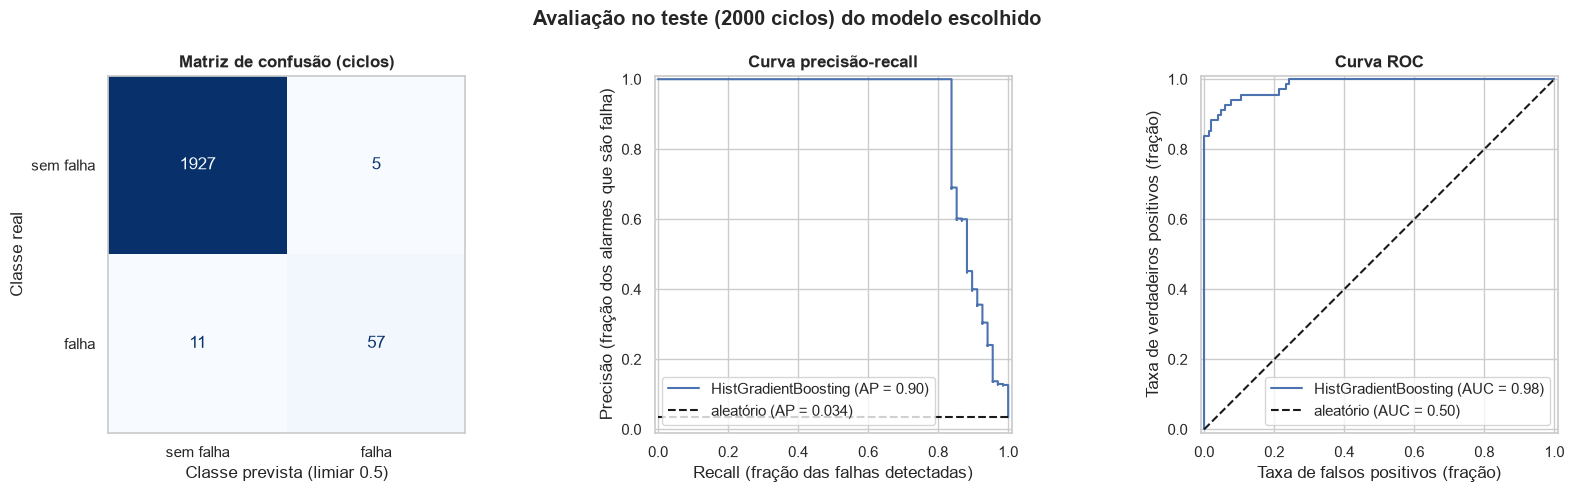

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ConfusionMatrixDisplay.from_predictions(
    y_te, pred, display_labels=["sem falha", "falha"], colorbar=False, cmap="Blues", ax=axes[0]
)
axes[0].grid(False)
axes[0].set_xlabel("Classe prevista (limiar 0.5)")
axes[0].set_ylabel("Classe real")
axes[0].set_title("Matriz de confusão (ciclos)")
nome_modelo = ROTULOS[melhor].replace("\n", "")
PrecisionRecallDisplay.from_predictions(
    y_te,
    proba,
    name=nome_modelo,
    plot_chance_level=True,
    chance_level_kw={"label": f"aleatório (AP = {y_te.mean():.3f})"},
    ax=axes[1],
)
axes[1].set_xlabel("Recall (fração das falhas detectadas)")
axes[1].set_ylabel("Precisão (fração dos alarmes que são falha)")
axes[1].set_title("Curva precisão-recall")
RocCurveDisplay.from_predictions(
    y_te,
    proba,
    name=nome_modelo,
    plot_chance_level=True,
    chance_level_kw={"label": "aleatório (AUC = 0.50)"},
    ax=axes[2],
)
axes[2].set_xlabel("Taxa de falsos positivos (fração)")
axes[2].set_ylabel("Taxa de verdadeiros positivos (fração)")
axes[2].set_title("Curva ROC")
fig.suptitle(f"Avaliação no teste ({len(teste)} ciclos) do modelo escolhido", fontweight="bold")
fig.tight_layout()
salvar_figura(fig, "04_avaliacao_teste")
plt.show()

### Recall por modo de falha

Os modos não entram como atributo (seriam vazamento: são a própria falha), mas servem para
perguntar **quais** falhas o modelo detecta. Um ciclo pode ter mais de um modo, então a soma
das linhas passa do total de falhas. "SEM MODO" são as falhas sem nenhum modo marcado.

In [12]:
rpm = mo.recall_por_modo(teste, pred)
salvar_tabela(rpm, "04_recall_por_modo")
rpm.round(3)

,modo,ciclos_no_teste,detectados,recall
0,TWF,10,1,0.1
1,HDF,29,29,1.0
2,PWF,13,13,1.0
3,OSF,16,16,1.0
4,RNF,4,0,0.0
5,SEM MODO,2,0,0.0


In [13]:
avaliados = predicoes.assign(pred=pred)
nao_detectadas = avaliados.query("falha == 1 and pred == 0")
so_twf = nao_detectadas["falha_twf"].eq(1) & nao_detectadas[COLS_MODOS].sum(axis=1).eq(1)
sem_falha = int((avaliados["falha"] == 0).sum())
print(f"falhas detectadas: {int(pred[y_te == 1].sum())} de {int(y_te.sum())}")
print(f"falhas não detectadas: {len(nao_detectadas)}")
print(
    f"  só TWF: {int(so_twf.sum())} · sem modo: {int(nao_detectadas[COLS_MODOS].sum(axis=1).eq(0).sum())}"
)
alarmes_falsos = int(((avaliados["falha"] == 0) & (avaliados["pred"] == 1)).sum())
print(f"alarmes falsos: {alarmes_falsos} em {sem_falha} ciclos sem falha")
rnf = teste[teste["falha_rnf"] == 1]
print(f"ciclos do teste com RNF = 1: {len(rnf)} · desses, com falha = 1: {int(rnf['falha'].sum())}")
nao_detectadas[["udi", "proba", *COLS_MODOS]].round(4)

falhas detectadas: 57 de 68
falhas não detectadas: 11
  só TWF: 9 · sem modo: 2
alarmes falsos: 5 em 1932 ciclos sem falha
ciclos do teste com RNF = 1: 4 · desses, com falha = 1: 0


,udi,proba,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
121,9175,0.0005,1,0,0,0,0
144,2672,0.0012,1,0,0,0,0
346,2865,0.0461,1,0,0,0,0
549,3696,0.0380,1,0,0,0,0
1293,7088,0.0992,1,0,0,0,0
1322,2942,0.0108,1,0,0,0,0
1327,9016,0.0044,0,0,0,0,0
1563,7850,0.0027,1,0,0,0,0
1657,8507,0.0004,0,0,0,0,0
1866,1997,0.0004,1,0,0,0,0


**Interpretação.**

- **Teste consistente com a validação cruzada:** PR-AUC 0,8976 no teste contra 0,8949 na
  validação cruzada e 0,8942 nas predições *out-of-fold*. Não há sinal de sobreajuste nem de
  vazamento (um teste muito acima da validação seria suspeito).
- **No limiar 0,5:** 57 das 68 falhas detectadas (recall 0,8382) com 5 alarmes falsos em 1.932
  ciclos sem falha (precisão 0,9194); MCC 0,8738. A curva precisão-recall mostra precisão 1,0
  até cerca de 84 % de recall: para detectar mais falhas, é preciso aceitar muitos alarmes.
- **HDF, PWF e OSF: 100 % detectadas** (29, 13 e 16 ciclos). São os modos gerados por regras
  determinísticas sobre ΔT, rotação, potência e esforço da ferramenta (notebook 01, seção 5),
  e os atributos de engenharia expõem essas regras diretamente.
- **O que escapa:** as 11 falhas não detectadas são 9 de TWF sozinho e 2 sem modo. TWF é a
  troca ou falha da ferramenta sorteada quando o desgaste está entre cerca de 200 e 240 min: a
  leitura do ciclo diz que a ferramenta está na zona de risco, mas não **qual** ciclo vai falhar.
  O único TWF detectado também tinha OSF. As falhas sem modo não seguem regra nenhuma.
- **RNF não é erro do modelo:** os 4 ciclos do teste com RNF = 1 têm todos `falha = 0` (são
  inconsistências de rótulo documentadas no notebook 01). O modelo prevê "sem falha", que é o
  rótulo correto pelo alvo publicado; o recall 0 dessa linha não conta como falha perdida.

## 6. Importância por permutação

Embaralha um atributo de cada vez no teste e mede quanto a PR-AUC cai (10 repetições). Queda
grande = o modelo depende daquele atributo; queda perto de zero = o modelo não usa, ou outro
atributo carrega a mesma informação. Mede o modelo como ele é, sem depender de como cada
algoritmo calcula importância internamente.

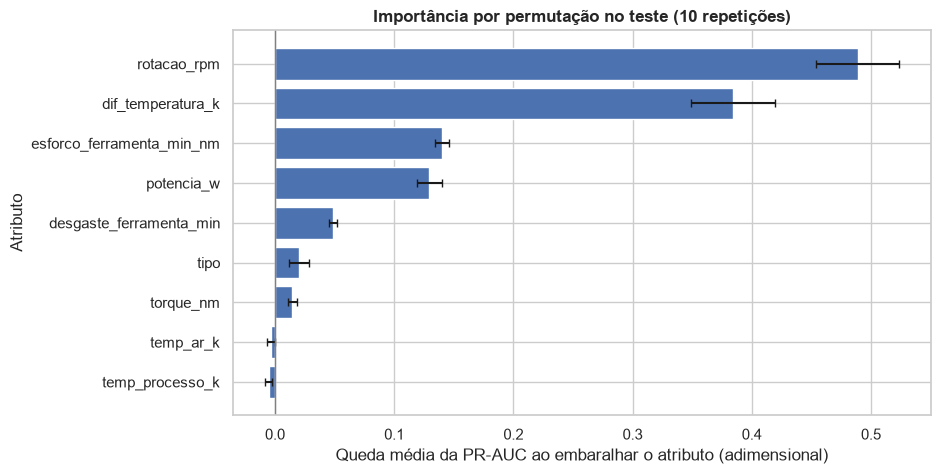

,atributo,importancia_media,importancia_dp
0,rotacao_rpm,0.4888,0.0349
1,dif_temperatura_k,0.3842,0.0351
2,esforco_ferramenta_min_nm,0.1403,0.0061
3,potencia_w,0.1296,0.0106
4,desgaste_ferramenta_min,0.0486,0.0032
5,tipo,0.0202,0.0081
6,torque_nm,0.0145,0.0038
7,temp_ar_k,-0.0032,0.0032
8,temp_processo_k,-0.0054,0.0029


In [14]:
imp = permutation_importance(
    final,
    X_te,
    y_te,
    scoring="average_precision",
    n_repeats=10,
    random_state=SEED,
    n_jobs=-1,
)
importancia = (
    pd.DataFrame(
        {
            "atributo": X_te.columns,
            "importancia_media": imp.importances_mean,
            "importancia_dp": imp.importances_std,
        }
    )
    .sort_values("importancia_media", ascending=False)
    .reset_index(drop=True)
)
salvar_tabela(importancia, "04_importancia_permutacao")

fig, ax = plt.subplots(figsize=(9, 5))
ordem_imp = importancia.iloc[::-1]
ax.barh(
    ordem_imp["atributo"],
    ordem_imp["importancia_media"],
    xerr=ordem_imp["importancia_dp"],
    capsize=3,
    color=sns.color_palette("deep")[0],
)
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("Queda média da PR-AUC ao embaralhar o atributo (adimensional)")
ax.set_ylabel("Atributo")
ax.set_title("Importância por permutação no teste (10 repetições)")
salvar_figura(fig, "04_importancia_permutacao")
plt.show()
importancia.round(4)

**Interpretação.**

- **Rotação (0,4888) e diferença de temperatura (0,3842)** são os atributos dos quais o modelo
  mais depende: juntos definem a regra de HDF, o modo mais frequente no teste (29 ciclos), e a
  rotação também entra na potência.
- **Esforço da ferramenta (0,1403) e potência (0,1296)** vêm em seguida: são as variáveis das
  regras de OSF e PWF. Dois dos três atributos de engenharia estão entre os quatro mais
  importantes.
- **Temperaturas do ar e do processo ficam em torno de zero** (−0,0032 e −0,0054): a informação
  delas chega ao modelo pela diferença ΔT. O torque (0,0145) também pesa pouco sozinho, porque
  já está dentro da potência e do esforço.

## 7. Interpretabilidade: árvore rasa

O modelo escolhido tem centenas de árvores e não dá para ler. Para enxergar as regras que os
dados sustentam, treinamos no treino, com `engenharia`, uma **árvore de profundidade 3**. Ela
não substitui o modelo escolhido; serve só para ler os limiares aprendidos e compará-los com as
regras de geração documentadas pela UCI.

Na figura, `value` são as contagens **ponderadas** por `class_weight="balanced"` (cada classe
soma 4.000 na raiz); a contagem real de ciclos e falhas em cada folha está na tabela abaixo dela.

|--- rotacao_rpm <= 1386.50
|   |--- dif_temperatura_k <= 8.65
|   |   |--- temp_processo_k <= 312.05
|   |   |   |--- class: 1
|   |   |--- temp_processo_k >  312.05
|   |   |   |--- class: 0
|   |--- dif_temperatura_k >  8.65
|   |   |--- esforco_ferramenta_min_nm <= 11013.60
|   |   |   |--- class: 0
|   |   |--- esforco_ferramenta_min_nm >  11013.60
|   |   |   |--- class: 1
|--- rotacao_rpm >  1386.50
|   |--- desgaste_ferramenta_min <= 204.50
|   |   |--- potencia_w <= 3496.14
|   |   |   |--- class: 1
|   |   |--- potencia_w >  3496.14
|   |   |   |--- class: 0
|   |--- desgaste_ferramenta_min >  204.50
|   |   |--- esforco_ferramenta_min_nm <= 10972.10
|   |   |   |--- class: 1
|   |   |--- esforco_ferramenta_min_nm >  10972.10
|   |   |   |--- class: 1



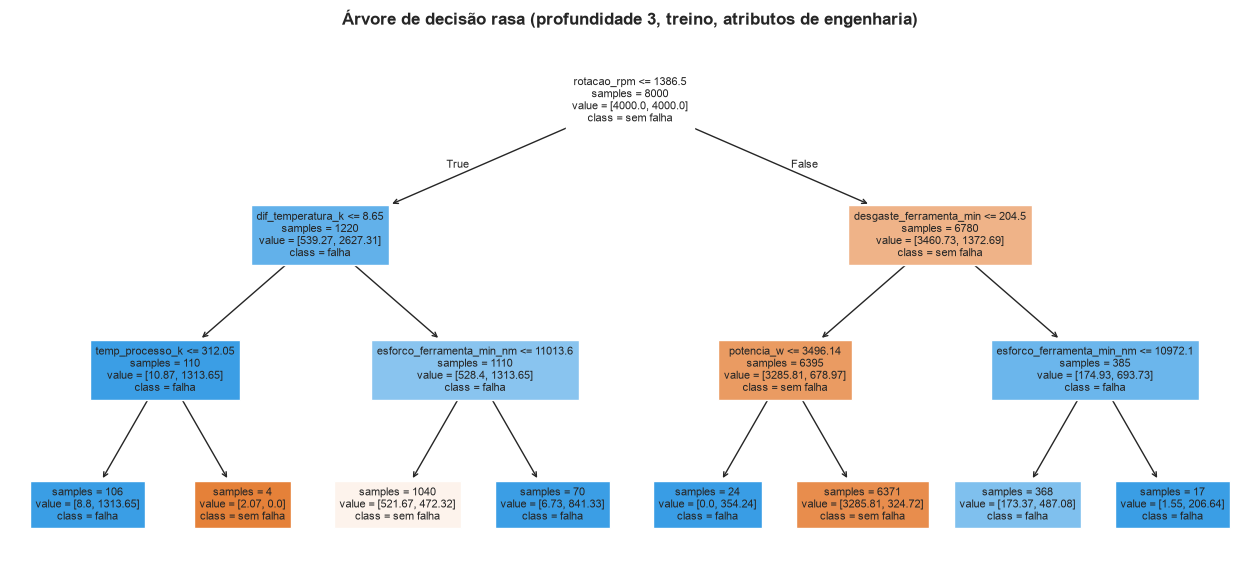

In [15]:
arv = (
    mo.montar_pipeline("arvore_decisao", ATRIBUTOS_ENGENHARIA)
    .set_params(modelo__max_depth=3)
    .fit(X_tr, y_tr)
)
nomes = ["tipo"] + [c for c in ATRIBUTOS_ENGENHARIA if c != "tipo"]
texto = export_text(arv.named_steps["modelo"], feature_names=nomes, decimals=2)
print(texto)
(DIR_TABELAS / "04_regras_arvore_rasa.txt").write_text(texto, encoding="utf-8")

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    arv.named_steps["modelo"],
    feature_names=nomes,
    class_names=["sem falha", "falha"],
    filled=True,
    impurity=False,
    precision=2,
    fontsize=8,
    ax=ax,
)
ax.set_title("Árvore de decisão rasa (profundidade 3, treino, atributos de engenharia)")
salvar_figura(fig, "04_arvore_rasa")
plt.show()

In [16]:
arvore = arv.named_steps["modelo"].tree_


def caminhos(no=0, condicoes=()):
    """Folha → condições do caminho desde a raiz."""
    if arvore.children_left[no] == -1:
        return {no: " e ".join(condicoes)}
    nome, limite = nomes[arvore.feature[no]], arvore.threshold[no]
    return {
        **caminhos(arvore.children_left[no], (*condicoes, f"{nome} <= {limite:.2f}")),
        **caminhos(arvore.children_right[no], (*condicoes, f"{nome} > {limite:.2f}")),
    }


X_tr_prep = arv.named_steps["prep"].transform(X_tr)
folhas = (
    pd.DataFrame(
        {
            "folha": arv.named_steps["modelo"].apply(X_tr_prep),
            "classe_prevista": arv.named_steps["modelo"].predict(X_tr_prep),
            "falha": y_tr.to_numpy(),
        }
    )
    .groupby(["folha", "classe_prevista"])["falha"]
    .agg(ciclos="size", falhas="sum")
    .reset_index()
    .assign(
        taxa_falha_pct=lambda t: (100 * t["falhas"] / t["ciclos"]).round(1),
        regra=lambda t: t["folha"].map(caminhos()),
    )
)
salvar_tabela(folhas, "04_folhas_arvore_rasa")
folhas

,folha,classe_prevista,ciclos,falhas,taxa_falha_pct,regra
0,3,1,106,89,84.0,rotacao_rpm <= 1386.50 e dif_temperatura_k <= 8.65 e temp_processo_k <= 312.05
1,4,0,4,0,0.0,rotacao_rpm <= 1386.50 e dif_temperatura_k <= 8.65 e temp_processo_k > 312.05
2,6,0,1040,32,3.1,rotacao_rpm <= 1386.50 e dif_temperatura_k > 8.65 e esforco_ferramenta_min_nm <= 11013.60
3,7,1,70,57,81.4,rotacao_rpm <= 1386.50 e dif_temperatura_k > 8.65 e esforco_ferramenta_min_nm > 11013.60
4,10,1,24,24,100.0,rotacao_rpm > 1386.50 e desgaste_ferramenta_min <= 204.50 e potencia_w <= 3496.14
5,11,0,6371,22,0.3,rotacao_rpm > 1386.50 e desgaste_ferramenta_min <= 204.50 e potencia_w > 3496.14
6,13,1,368,33,9.0,rotacao_rpm > 1386.50 e desgaste_ferramenta_min > 204.50 e esforco_ferramenta_min_nm <= 10972.10
7,14,1,17,14,82.4,rotacao_rpm > 1386.50 e desgaste_ferramenta_min > 204.50 e esforco_ferramenta_min_nm > 10972.10


**Comparação com as regras de geração da UCI.** Sem receber nenhuma regra, a árvore reencontra
os limiares documentados:

| Modo | Regra documentada | Corte aprendido pela árvore | Folha (ciclos do treino, falhas) |
|---|---|---|---|
| HDF | ΔT < 8,6 K **e** rotação < 1380 rpm | `dif_temperatura_k <= 8.65` e `rotacao_rpm <= 1386.50` | 106 ciclos, 89 falhas (84,0 %) |
| PWF | potência < 3500 W **ou** > 9000 W | `potencia_w <= 3496.14` | 24 ciclos, 24 falhas (100 %) |
| OSF | esforço > 11.000 (L) / 12.000 (M) / 13.000 (H) min·N·m | `esforco_ferramenta_min_nm > 11013.60` e `> 10972.10` | 70 ciclos, 57 falhas (81,4 %) e 17 ciclos, 14 falhas (82,4 %) |
| TWF | troca da ferramenta sorteada com desgaste de ~200 a 240 min | `desgaste_ferramenta_min > 204.50` | 368 ciclos, 33 falhas (9,0 %) |

- Os cortes de HDF, PWF e OSF ficam a menos de 1 % dos valores documentados. O corte de OSF
  fica perto de 11.000, o limite do tipo L, que é 60 % dos ciclos; com profundidade 3 não
  sobra nível para separar M e H.
- O limite superior de PWF (9000 W) não aparece: com só 3 níveis, a árvore gasta os cortes nas
  regras que explicam mais falhas.
- **TWF mostra o limite do problema:** a árvore identifica a zona de risco (desgaste acima de
  204,50 min), mas só 33 dos 368 ciclos dessa zona falham (9,0 %). Ela marca a folha inteira como
  "falha" por causa do `class_weight="balanced"`, o que no limiar padrão vira muitos alarmes
  falsos. É a mesma razão por que o modelo escolhido deixa passar 9 das 10 falhas TWF do teste:
  a leitura do ciclo mostra que a ferramenta está gasta, mas não diz em qual ciclo ela vai
  falhar.
- O corte `temp_processo_k <= 312.05` separa só 4 ciclos sem falha: é ruído de amostra, não uma
  regra física.

## Conclusões da etapa

- **Modelo escolhido:** HistGradientBoosting com os 9 atributos de `engenharia`, ajustado por
  busca aleatória (taxa de aprendizado 0,03, 400 iterações, até 63 folhas, mínimo de 10 ciclos
  por folha, L2 = 1,0), com PR-AUC média de 0,8949 na validação cruzada
  (`04_modelo_escolhido.csv`).
- **Engenharia de atributos é o fator que mais pesa:** melhora todos os modelos, com ganho de
  PR-AUC de 0,091 no HistGradientBoosting (0,799 → 0,890) e de 0,259 na árvore de decisão
  (0,535 → 0,794). O ajuste de hiperparâmetros acrescentou só 0,0049, abaixo do desvio entre
  dobras (`04_comparacao_cv.csv`, `04_busca_hiperparametros.csv`).
- **Desempenho no teste consistente com a validação:** PR-AUC 0,8976, ROC-AUC 0,9842,
  recall 0,8382 (57 de 68 falhas), precisão 0,9194 (5 alarmes falsos em 1.932 ciclos sem
  falha), MCC 0,8738 no limiar 0,5 (`04_metricas_teste.csv`). Sem sinal de sobreajuste nem de
  vazamento.
- **Detecta 100 % de HDF, PWF e OSF** no teste e deixa passar 9 das 10 falhas TWF e as 2 falhas
  sem modo (`04_recall_por_modo.csv`). Os 4 ciclos com RNF no teste têm rótulo `falha = 0`.
- **O modelo usa a física do processo:** rotação e ΔT são os atributos mais importantes,
  seguidos de esforço da ferramenta e potência (`04_importancia_permutacao.csv`); uma árvore de
  profundidade 3 reencontra os limiares documentados de HDF, PWF e OSF com erro menor que 1 %.
- **Limitação principal:** o dataset é sintético, gerado por essas regras; o desempenho não se
  transfere automaticamente para uma máquina real, e o erro que sobra é o das falhas que não
  dependem da leitura do ciclo (TWF e sem modo).
- **Entregas para o notebook 05:** probabilidades *out-of-fold* do treino
  (`04_oof_treino.csv`, 8.000 linhas) para escolher o limiar pelo custo, e probabilidades do
  teste (`04_predicoes_teste.csv`, 2.000 linhas) para medir as estratégias de manutenção.